In [1]:
print("Hello Richa")

Hello Richa


# Iris Flower Classification
**Author:** Richa Pandey | **Track:** Data Science | **Internship:** Oasis Infobyte

## Objective
To build a machine learning model that predicts the species of an iris flower (Setosa, Versicolor or Virginica) from its sepal and petal measurements.

## Dataset
The built-in Iris dataset from scikit-learn (150 samples, 4 features, 3 classes).

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")

In [3]:
# Load the Iris dataset and convert it into a DataFrame
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# Basic exploratory data analysis
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values:\n", df.isnull().sum())
print("\nSpecies count:\n", df['species'].value_counts())

Shape: (150, 5)

Data types:
 sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object

Null values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species count:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [5]:
# Descriptive statistics
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Observations
- The dataset contains 150 rows and 5 columns (4 numerical features and 1 species label).
- There are no missing values, so no data cleaning is required.
- Each species (setosa, versicolor, virginica) has exactly 50 samples, so the dataset is perfectly balanced.
- Petal length has the widest range (1.0 to 6.9 cm) and the highest standard deviation (1.77), which suggests it varies a lot between species.
- Sepal width has the smallest average (3.06 cm) and the narrowest spread among sepal features.
- The mean sepal length is 5.84 cm and the mean petal length is 3.76 cm.

## Data Visualisation

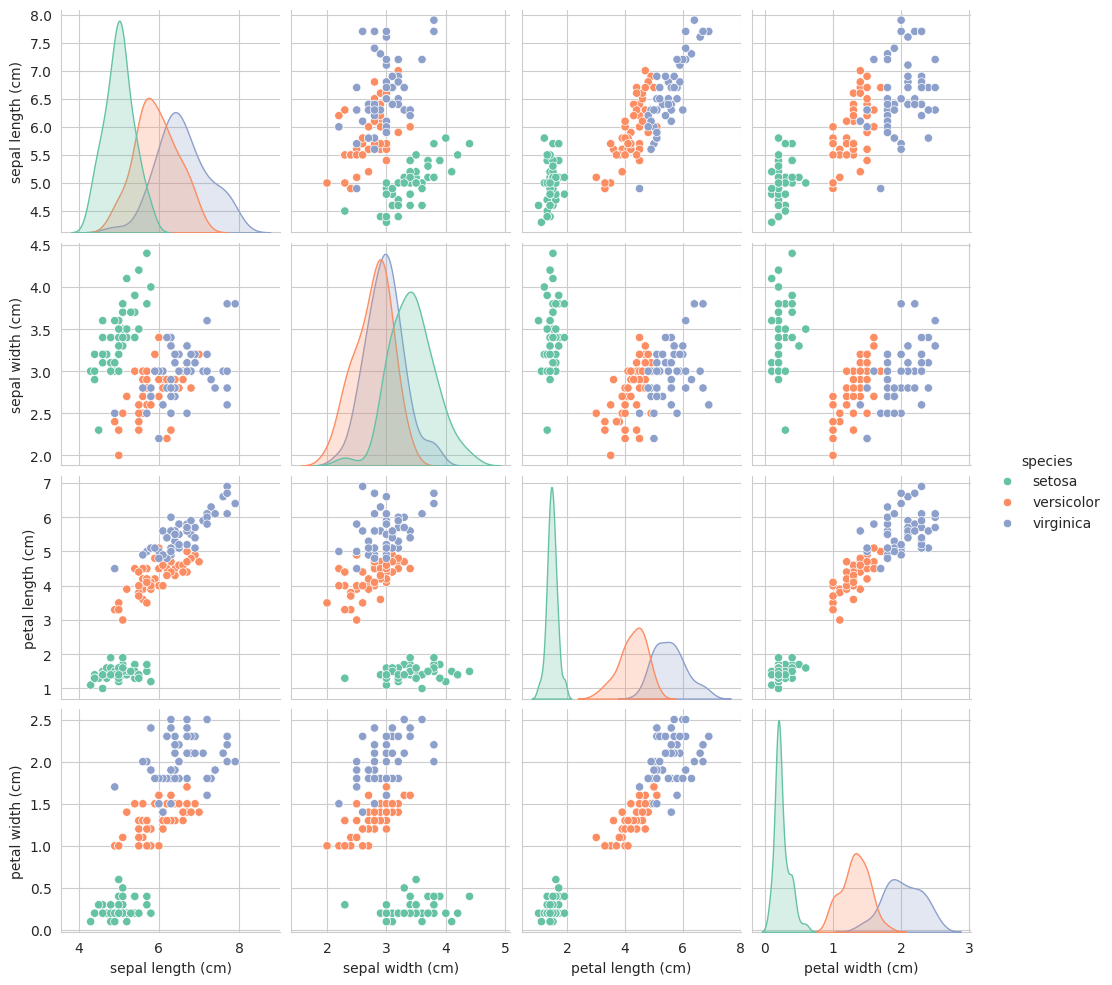

In [6]:
# Pairplot: shows relationship between every pair of features, coloured by species
sns.pairplot(df, hue='species', palette='Set2')
plt.show()

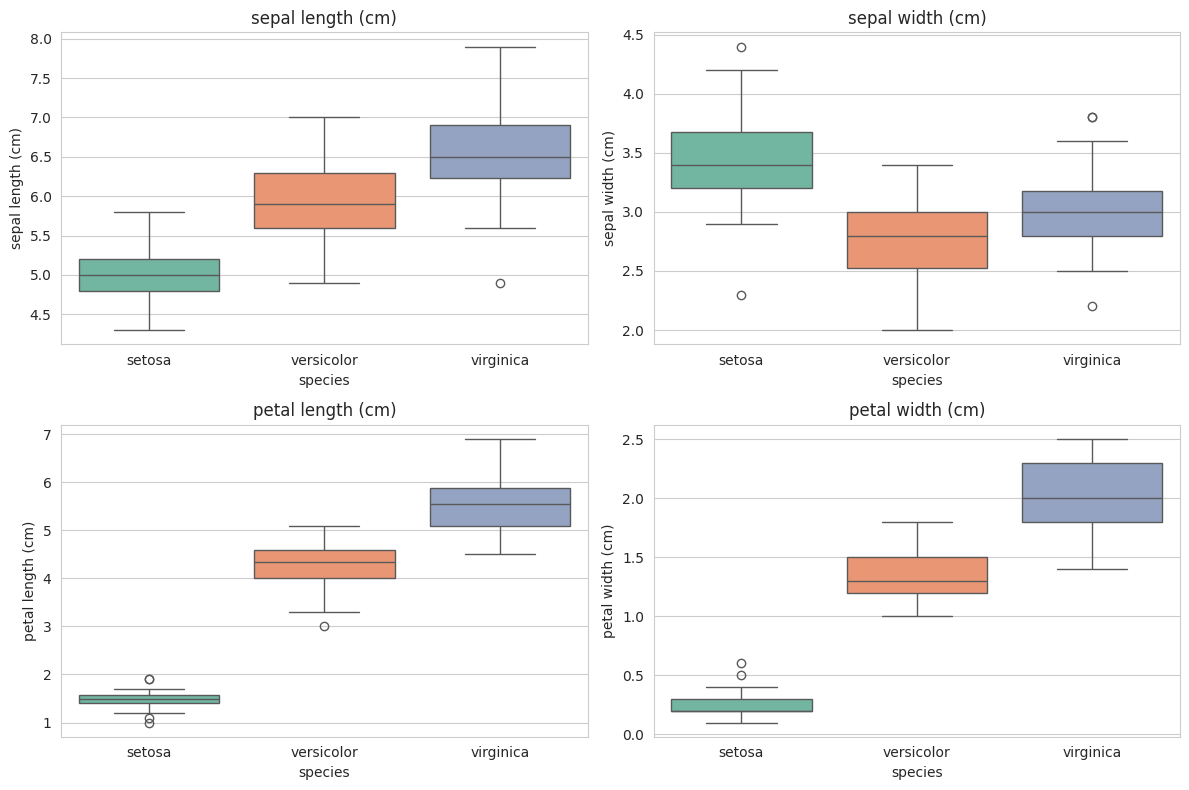

In [7]:
# Box plots: distribution of each feature for every species
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flatten(), iris.feature_names):
    sns.boxplot(x='species', y=feature, hue='species', data=df,
                ax=ax, palette='Set2', legend=False)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## Feature Analysis
- **Setosa** is clearly separated from the other two species. In the pairplot it forms its own cluster, especially in petal length and petal width.
- **Versicolor and Virginica** overlap slightly, mostly in the sepal measurements, but they are still fairly separable using the petal measurements.
- **Petal length and petal width** are the most discriminative features. In the box plots, the three species have clearly different medians and very little overlap in these two features.
- **Sepal width** shows the most overlap among the species, so it is the least useful feature for classification.
- The pairplot shows a strong positive relationship between petal length and petal width, which means these two features move together.
- Overall, the data is well separated, so even simple models are expected to give high accuracy.

## Train-Test Split
The data is split into 80% training and 20% testing sets. Stratification keeps the species proportions equal in both sets.

In [8]:
# Separate features (X) and target (y)
X = df.drop(columns='species')
y = df['species']

# 80/20 split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (120, 4)
Testing set: (30, 4)


## Model Training and Evaluation
Three classification models are trained and compared: Logistic Regression, K-Nearest Neighbours (KNN) and Decision Tree.

In [9]:
# Create the three models
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

# Train each model on the training data and store its predictions
predictions = {}
accuracies = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    accuracies[name] = accuracy_score(y_test, predictions[name])

print("All models trained successfully")

All models trained successfully


In [10]:
# Accuracy and classification report for each model
for name in models:
    print("=" * 55)
    print(name)
    print("Accuracy:", round(accuracies[name], 4))
    print("\nClassification Report:\n")
    print(classification_report(y_test, predictions[name]))

Logistic Regression
Accuracy: 0.9667

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

KNN
Accuracy: 1.0

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Decision Tree
Accuracy: 0.9333

Classification Report:

              precision    recall  f1-score   support

      setosa       1.0

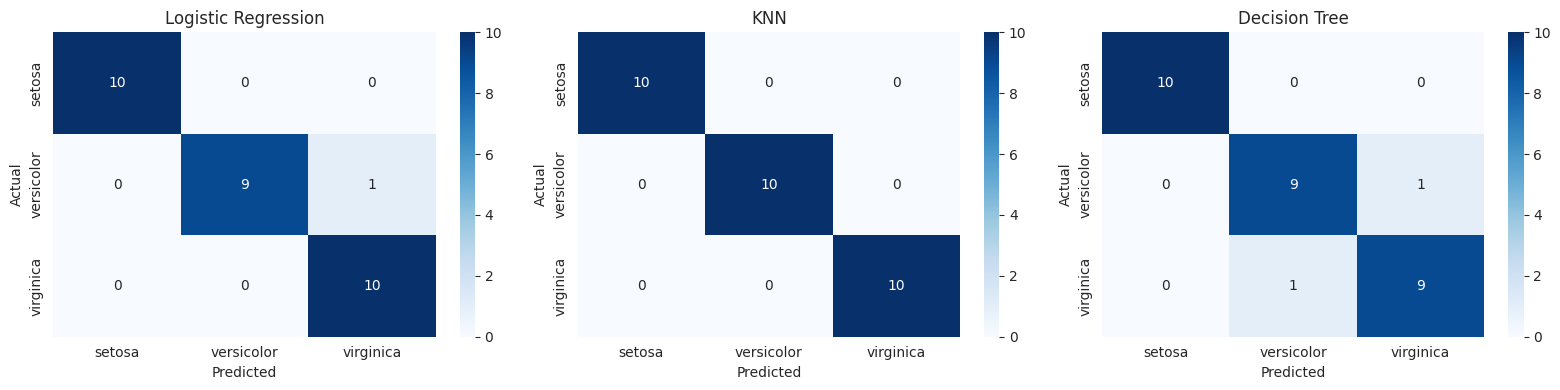

In [11]:
# Confusion matrix for each model
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name], labels=iris.target_names)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [12]:
# Compare all models side by side
comparison = pd.DataFrame({
    "Model": list(accuracies.keys()),
    "Accuracy": list(accuracies.values())
}).sort_values("Accuracy", ascending=False).reset_index(drop=True)

comparison

,Model,Accuracy
0,KNN,1.000000
1,Logistic Regression,0.966667
2,Decision Tree,0.933333


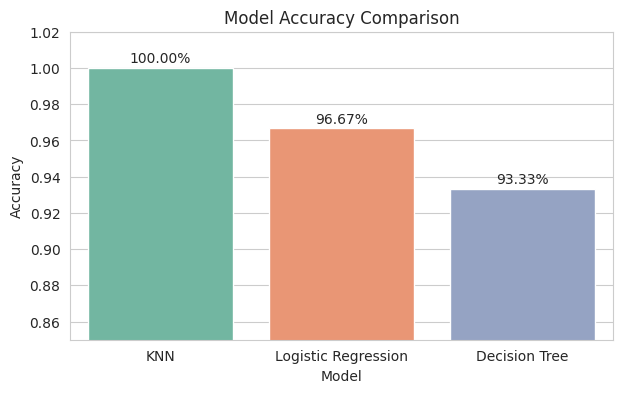

In [13]:
# Bar chart of model accuracies
plt.figure(figsize=(7, 4))
sns.barplot(x="Model", y="Accuracy", hue="Model", data=comparison, palette="Set2", legend=False)
plt.ylim(0.85, 1.02)
plt.title("Model Accuracy Comparison")
for i, acc in enumerate(comparison["Accuracy"]):
    plt.text(i, acc + 0.003, f"{acc*100:.2f}%", ha="center")
plt.show()

## Best Model
- **Best model:** K-Nearest Neighbours (KNN) with an accuracy of **100%** on the test set.
- Logistic Regression scored **96.67%** (1 misclassified sample out of 30) and Decision Tree scored **93.33%** (2 misclassified samples out of 30).
- KNN classified all 30 test samples correctly, so its precision, recall and F1-score are 1.00 for all three species.
- Setosa was classified correctly by every model. The few errors made by the other two models were between Versicolor and Virginica, which overlap slightly in the feature space.
- The test set has only 30 samples, so one wrong prediction changes accuracy by about 3.3%. The three models are therefore close in performance, and the ranking could change with a different random split.
- **Justification:** KNN is declared the best model because it has the highest accuracy and the fewest misclassifications. Logistic Regression is a strong, simple alternative.

## Conclusion
- The Iris dataset is clean, balanced and well separated, so all three models achieved over 93% accuracy.
- Petal length and petal width are the most useful features for telling the species apart.
- KNN gave the best result (100% accuracy), followed by Logistic Regression (96.67%) and Decision Tree (93.33%).
- A model like this can be used in botany and agriculture to identify plant species quickly from simple measurements.
- Future improvement: use cross-validation instead of a single split to get a more reliable comparison.

In [14]:
# Predict the species of a new flower
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=iris.feature_names)
print("Predicted species:", models["KNN"].predict(new_flower)[0])

Predicted species: setosa
